# AI Layoff Risk Predictor: Logistic Regression
**AI101 Mini-Project | Team 00** (reference example)

**Problem statement.** Predict whether an employee's layoff risk is **Low, Medium or High** from job, personal and AI-use features.

**Motivation.** As AI tools spread through workplaces, it helps to know which job traits go with higher layoff risk, for example routine tasks versus creative work.

**Task.** Multi-class classification with **Logistic Regression** (scikit-learn).

**Dataset.** Kaggle, *AI Impact on Jobs and Layoff Risk Dataset* (shivasingh4945). It is synthetic: 20,000 rows, 16 columns (9 numeric features, 6 categorical features and the label `Layoff_Risk`).

**Outline:** 1. Load data, 2. Data understanding (mean, median, standard deviation, covariance, correlation), 3. Preprocessing and train/test split, 4. Model, training functions and training plots, 5. Evaluation on training and testing sets, 6. Interpretation.

In [ ]:
%matplotlib inline
from pathlib import Path
import numpy as np

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, auc, classification_report,
                             f1_score, log_loss, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize

RANDOM_STATE = 42
DATA_PATH =  "ai-impact-jobs-layoff-risk-dataset.csv"  
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)
TARGET = "Layoff_Risk"
LABELS = ["Low", "Medium", "High"]
COLORS = {"Low": "#2a9d8f", "Medium": "#e9c46a", "High": "#c0392b"}
pd.set_option("display.width", 200)

## 1. Load the data

In [89]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()

Rows: 20,000 | Columns: 16


,Age,Education_Level,Years_of_Experience,Industry,Job_Role,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours,Layoff_Risk
0,59,Master's,6,Finance,Accountant,Medium,Entry,84,21,94,Medium,5,7,40,26,High
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30,84,68,Low,2,2,14,9,Low
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12,86,71,Low,0,1,6,3,Low
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90,18,21,Medium,3,10,67,26,High
4,49,High School,12,Finance,Auditor,Small,Entry,49,52,72,Medium,5,13,26,19,Medium


In [90]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Age                         20000 non-null  int64
 1   Education_Level             20000 non-null  str  
 2   Years_of_Experience         20000 non-null  int64
 3   Industry                    20000 non-null  str  
 4   Job_Role                    20000 non-null  str  
 5   Company_Size                20000 non-null  str  
 6   Job_Level                   20000 non-null  str  
 7   Routine_Task_Percentage     20000 non-null  int64
 8   Creativity_Requirement      20000 non-null  int64
 9   Human_Interaction_Level     20000 non-null  int64
 10  AI_Adoption_Level           20000 non-null  str  
 11  Number_of_AI_Tools_Used     20000 non-null  int64
 12  AI_Usage_Hours_Per_Week     20000 non-null  int64
 13  Tasks_Automated_Percentage  20000 non-null  int64
 14  AI_Training_Hours

## 2. Data understanding with statistics

In [91]:
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols + [TARGET]]
print("Numeric features:", num_cols)
print("Categorical features:", cat_cols)


stats = df[num_cols].agg(["mean", "median", "std", "min", "max"]).T.round(2)
stats

Numeric features: ['Age', 'Years_of_Experience', 'Routine_Task_Percentage', 'Creativity_Requirement', 'Human_Interaction_Level', 'Number_of_AI_Tools_Used', 'AI_Usage_Hours_Per_Week', 'Tasks_Automated_Percentage', 'AI_Training_Hours']
Categorical features: ['Education_Level', 'Industry', 'Job_Role', 'Company_Size', 'Job_Level', 'AI_Adoption_Level']


,mean,median,std,min,max
Age,40.36,40.0,11.53,21.0,60.0
Years_of_Experience,7.27,7.0,4.72,0.0,32.0
Routine_Task_Percentage,51.89,52.0,24.44,10.0,94.0
Creativity_Requirement,47.79,48.0,26.10,0.0,100.0
Human_Interaction_Level,60.06,62.0,22.27,20.0,99.0
Number_of_AI_Tools_Used,2.46,2.0,2.10,0.0,10.0
AI_Usage_Hours_Per_Week,6.77,5.0,6.09,0.0,30.0
Tasks_Automated_Percentage,37.23,35.0,20.00,4.0,93.0
AI_Training_Hours,12.62,8.0,13.55,0.0,79.0


Layoff_Risk
Low       6602
Medium    6601
High      6797
Name: count, dtype: int64


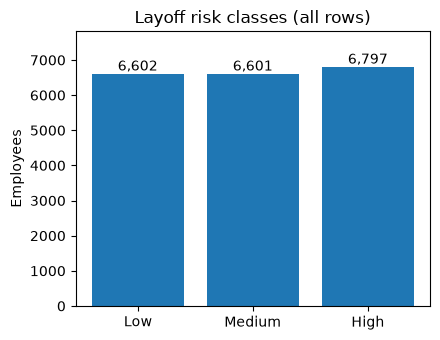

In [92]:
counts = df[TARGET].value_counts().reindex(LABELS)
print(counts)

fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.bar(counts.index, counts.values)
for i, v in enumerate(counts.values):
    ax.text(i, v + 100, f"{v:,}", ha="center")
ax.set(title="Layoff risk classes (all rows)", ylabel="Employees", ylim=(0, counts.max() * 1.15))
fig.tight_layout()
fig.savefig(OUT_DIR / "class_balance.png", dpi=150)
plt.show()

In [93]:
cov = df[num_cols].cov().round(1)
cov

,Age,Years_of_Experience,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours
Age,132.9,20.7,0.1,0.2,0.6,0.1,0.3,-0.1,-0.2
Years_of_Experience,20.7,22.3,-0.4,0.6,1.5,-0.0,-0.1,-0.4,-0.2
Routine_Task_Percentage,0.1,-0.4,597.2,-591.8,-9.1,33.9,100.1,435.0,198.0
Creativity_Requirement,0.2,0.6,-591.8,681.2,9.5,-33.8,-99.6,-431.8,-196.7
Human_Interaction_Level,0.6,1.5,-9.1,9.5,495.9,-0.3,-2.0,-4.7,-3.6
Number_of_AI_Tools_Used,0.1,-0.0,33.9,-33.8,-0.3,4.4,10.1,24.6,21.0
AI_Usage_Hours_Per_Week,0.3,-0.1,100.1,-99.6,-2.0,10.1,37.0,72.7,64.4
Tasks_Automated_Percentage,-0.1,-0.4,435.0,-431.8,-4.7,24.6,72.7,399.8,143.3
AI_Training_Hours,-0.2,-0.2,198.0,-196.7,-3.6,21.0,64.4,143.3,183.7


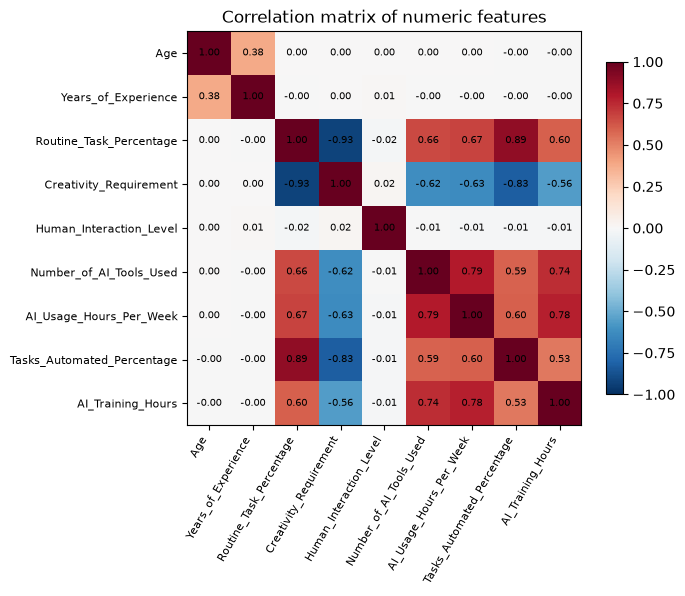

In [94]:
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), num_cols, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(num_cols)), num_cols, fontsize=8)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation matrix of numeric features")
fig.tight_layout()
fig.savefig(OUT_DIR / "correlation_heatmap.png", dpi=150)
plt.show()

In [95]:
risk_score = df[TARGET].map({"Low": 0, "Medium": 1, "High": 2})
df[num_cols].corrwith(risk_score).round(2).sort_values()

Creativity_Requirement       -0.75
Human_Interaction_Level      -0.16
Years_of_Experience          -0.10
Age                          -0.04
AI_Training_Hours             0.43
AI_Usage_Hours_Per_Week       0.50
Number_of_AI_Tools_Used       0.50
Tasks_Automated_Percentage    0.75
Routine_Task_Percentage       0.78
dtype: float64

In [96]:
df.groupby(TARGET)[num_cols].mean().round(1).reindex(LABELS).T

Layoff_Risk,Low,Medium,High
Age,40.9,40.3,39.9
Years_of_Experience,7.9,7.3,6.7
Routine_Task_Percentage,28.5,51.3,75.2
Creativity_Requirement,71.9,48.3,23.8
Human_Interaction_Level,64.6,59.7,55.9
Number_of_AI_Tools_Used,1.3,2.3,3.8
AI_Usage_Hours_Per_Week,3.3,6.2,10.8
Tasks_Automated_Percentage,19.5,35.7,56.0
AI_Training_Hours,6.0,11.4,20.2


**What the statistics tell us**
- Features are on very different scales (standard deviations range from about 2 to 26), so they must be **scaled** before Logistic Regression.
- Means and medians are close for most features, so they are roughly symmetric. `AI_Training_Hours` is right-skewed (mean 12.6, median 8).
- Risk goes up with `Routine_Task_Percentage` (correlation 0.78) and `Tasks_Automated_Percentage` (0.75). It goes down with `Creativity_Requirement` (-0.75).
- Some features are strongly correlated with each other, for example `Routine_Task_Percentage` and `Creativity_Requirement` (-0.93). This makes individual coefficients harder to read later.
- The three classes are balanced, so accuracy is a fair metric.

## 3. Preprocessing and train/test split
1. Check for missing values and duplicate rows, and drop them if present.
2. Split into **80% train / 20% test**, stratified on the label. We split *before* scaling so no test information leaks into training.
3. Scale numeric features with `StandardScaler` (normalisation to mean 0, standard deviation 1), fitted on the training set only.
4. One-hot encode the categorical features (the model needs numbers).
5. Feature selection: we keep all features. Logistic Regression uses L2 regularisation, which copes with correlated inputs.

In [97]:
print("Missing values:", int(df.isna().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
df = df.drop_duplicates().dropna()

X = df.drop(columns=TARGET)
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print("Class share in train:", y_train.value_counts(normalize=True).round(3).to_dict())

Missing values: 0 | Duplicate rows: 0
Train: (16000, 15) | Test: (4000, 15)
Class share in train: {'High': 0.34, 'Low': 0.33, 'Medium': 0.33}


In [ ]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])
X_train_t = preprocessor.fit_transform(X_train) 
X_test_t = preprocessor.transform(X_test)         
feature_names = preprocessor.get_feature_names_out()
print(f"Features after preprocessing: {X_train_t.shape[1]} ({len(num_cols)} numeric + one-hot columns)")

Features after preprocessing: 54 (9 numeric + one-hot columns)


## 4. Model, training functions and training plots
**Logistic Regression** gives each class a score (a weighted sum of the features) and turns the scores into probabilities with the softmax function. Training minimises the **log-loss** (cross-entropy) plus an L2 penalty, using the L-BFGS optimiser.

`training_curve()` retrains the model with 1, 2, 3, ... L-BFGS iterations and records the loss and accuracy on the train and test sets, so we can plot how training progresses.

In [99]:
def training_curve_gd(X_tr, y_tr, X_te, y_te, max_epochs=100):
    clf = SGDClassifier(loss='log_loss', random_state=42)
    classes = np.unique(y_tr)
    rows = []
    
    for epoch in range(1, max_epochs + 1):
        clf.partial_fit(X_tr, y_tr, classes=classes)
        
        rows.append({
            "epoch": epoch,
            "train_loss": log_loss(y_tr, clf.predict_proba(X_tr), labels=classes),
            "test_loss": log_loss(y_te, clf.predict_proba(X_te), labels=classes),
            "train_acc": clf.score(X_tr, y_tr),
            "test_acc": clf.score(X_te, y_te)
        })
    return pd.DataFrame(rows)

history = training_curve_gd(X_train_t, y_train, X_test_t, y_test, max_epochs=100)
history

,epoch,train_loss,test_loss,train_acc,test_acc
0,1,0.535620,0.548898,0.867062,0.86425
1,2,0.340891,0.351442,0.894500,0.88850
2,3,0.305437,0.314965,0.909813,0.90225
3,4,0.298583,0.306777,0.916937,0.90900
4,5,0.297591,0.304849,0.923750,0.91500
...,...,...,...,...,...
95,96,0.309641,0.315368,0.933312,0.92700
96,97,0.309636,0.315361,0.933375,0.92700
97,98,0.309631,0.315353,0.933375,0.92700
98,99,0.309625,0.315346,0.933375,0.92675


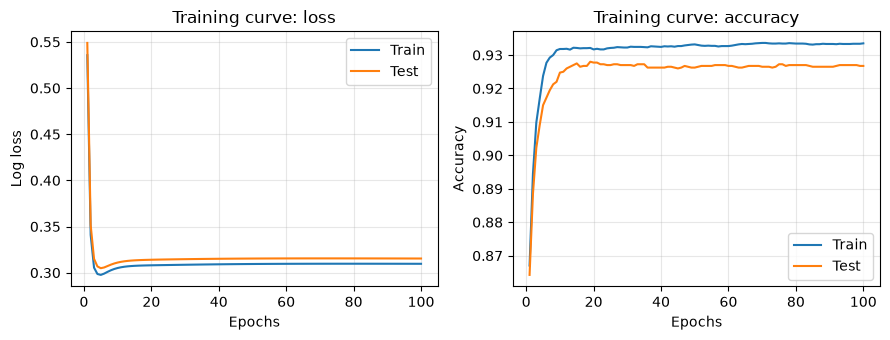

In [100]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

axes[0].plot(history["epoch"], history["train_loss"], label="Train")
axes[0].plot(history["epoch"], history["test_loss"], label="Test")
axes[0].set(xlabel="Epochs", ylabel="Log loss", title="Training curve: loss")


axes[1].plot(history["epoch"], history["train_acc"], label="Train")
axes[1].plot(history["epoch"], history["test_acc"], label="Test")
axes[1].set(xlabel="Epochs", ylabel="Accuracy", title="Training curve: accuracy")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig("training_curve_gd.png", dpi=150)
plt.show()

In [101]:
model = LogisticRegression(max_iter=1000)   
model.fit(X_train_t, y_train)
print("Converged after", int(model.n_iter_[0]), "iterations | classes:", list(model.classes_))

Converged after 46 iterations | classes: ['High', 'Low', 'Medium']


## 5. Evaluation on training and testing sets
We report accuracy, precision, recall and F1 (macro = average over the three classes) plus the confusion matrix, on both sets. Comparing train and test shows whether the model overfits. RMSE is a regression metric, so it does not apply to this classification task.

In [102]:
def evaluate(model, X_t, y_true):
    pred = model.predict(X_t)
    proba = model.predict_proba(X_t)
    avg = {"average": "macro", "zero_division": 0}
    metrics = {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision (macro)": precision_score(y_true, pred, **avg),
        "Recall (macro)": recall_score(y_true, pred, **avg),
        "F1 (macro)": f1_score(y_true, pred, **avg),
         "ROC AUC (macro, one-vs-rest)": roc_auc_score(y_true, proba, multi_class="ovr",
                                                             average="macro", labels=model.classes_),
    }
    return metrics, pred

train_metrics, train_pred = evaluate(model, X_train_t, y_train)
test_metrics, test_pred = evaluate(model, X_test_t, y_test)
results = pd.DataFrame({"Train": train_metrics, "Test": test_metrics})
(OUT_DIR / "metrics.json").write_text(results.to_json(indent=2))
results

,Train,Test
Accuracy,0.941000,0.937750
Precision (macro),0.940924,0.937548
Recall (macro),0.940860,0.937530
F1 (macro),0.940888,0.937535
"ROC AUC (macro, one-vs-rest)",0.994580,0.993885


In [103]:
print("TRAIN set: per-class precision, recall and F1")
print(classification_report(y_train, train_pred, labels=LABELS, digits=3))
print("TEST set: per-class precision, recall and F1")
print(classification_report(y_test, test_pred, labels=LABELS, digits=3))

TRAIN set: per-class precision, recall and F1
              precision    recall  f1-score   support

         Low      0.956     0.954     0.955      5282
      Medium      0.908     0.914     0.911      5281
        High      0.959     0.955     0.957      5437

    accuracy                          0.941     16000
   macro avg      0.941     0.941     0.941     16000
weighted avg      0.941     0.941     0.941     16000

TEST set: per-class precision, recall and F1
              precision    recall  f1-score   support

         Low      0.952     0.948     0.950      1320
      Medium      0.907     0.905     0.906      1320
        High      0.954     0.960     0.957      1360

    accuracy                          0.938      4000
   macro avg      0.938     0.938     0.938      4000
weighted avg      0.938     0.938     0.938      4000



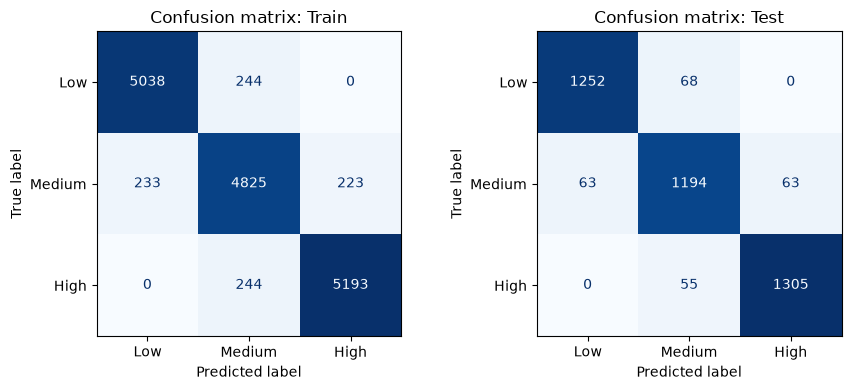

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, y_true, pred, title in [(axes[0], y_train, train_pred, "Train"), (axes[1], y_test, test_pred, "Test")]:
    ConfusionMatrixDisplay.from_predictions(y_true, pred, labels=LABELS, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"Confusion matrix: {title}")
fig.tight_layout()
fig.savefig(OUT_DIR / "confusion_matrices.png", dpi=150)
plt.show()

**ROC curve.** The ROC curve plots the true positive rate against the false positive rate as the decision threshold changes. The area under it (**AUC**) is 1.0 for a perfect model and 0.5 for random guessing. With three classes we use **one-vs-rest**: each class is treated as "positive" against the other two, giving one curve per class.

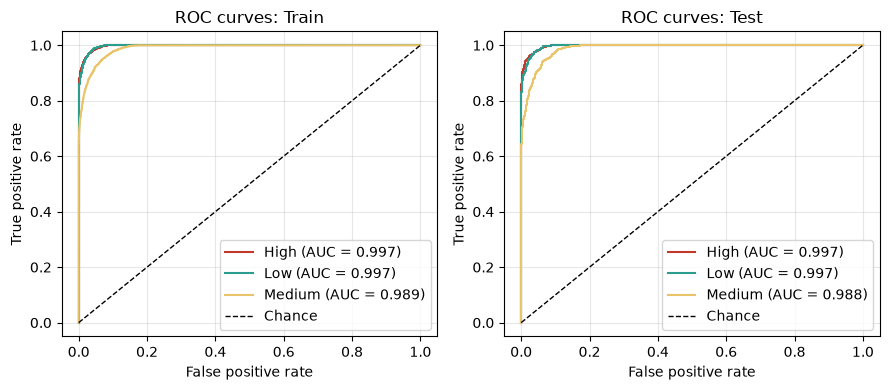

In [ ]:
def plot_roc(ax, model, X_t, y_true, title):
    proba = model.predict_proba(X_t)
    y_bin = label_binarize(y_true, classes=model.classes_) 
    for i, label in enumerate(model.classes_):
        fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i])
        ax.plot(fpr, tpr, color=COLORS[label], label=f"{label} (AUC = {auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
    ax.set(title=title, xlabel="False positive rate", ylabel="True positive rate")
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
plot_roc(axes[0], model, X_train_t, y_train, "ROC curves: Train")
plot_roc(axes[1], model, X_test_t, y_test, "ROC curves: Test")
fig.tight_layout()
fig.savefig(OUT_DIR / "roc_curves.png", dpi=150)
plt.show()

## 6. Interpretation of results
The coefficients show which features push the prediction towards the **High** risk class. A positive coefficient raises the chance of High risk, a negative one lowers it. Numeric features are standardised, so a coefficient is the effect of a 1-standard-deviation increase. One-hot columns are 0/1, so a coefficient is the effect of being in that category compared with the other categories of the same feature. Compare sizes loosely across these two kinds.

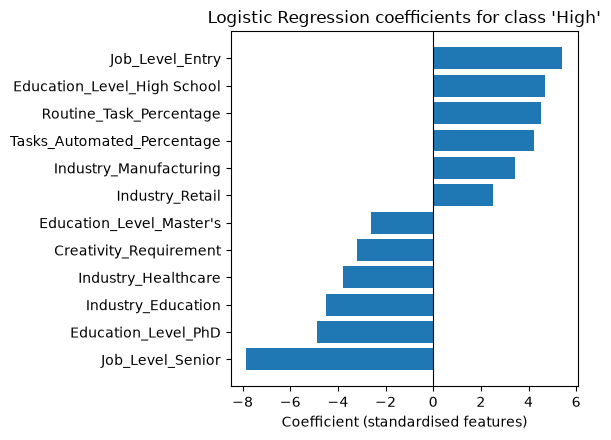

Job_Level_Senior              -7.84
Education_Level_PhD           -4.86
Industry_Education            -4.48
Industry_Healthcare           -3.80
Creativity_Requirement        -3.20
Education_Level_Master's      -2.60
Industry_Retail                2.51
Industry_Manufacturing         3.44
Tasks_Automated_Percentage     4.25
Routine_Task_Percentage        4.53
Education_Level_High School    4.67
Job_Level_Entry                5.42
Name: High, dtype: float64

In [106]:
names = [n.split("__", 1)[1] for n in feature_names]
coef = pd.DataFrame(model.coef_, index=model.classes_, columns=names)
high = coef.loc["High"].sort_values()
top = pd.concat([high.head(6), high.tail(6)])

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.barh(top.index, top.values)
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Logistic Regression coefficients for class 'High'", xlabel="Coefficient (standardised features)")
fig.tight_layout()
fig.savefig(OUT_DIR / "coefficients_high_risk.png", dpi=150)
plt.show()
top.round(2)

## Final analysis

**Performance.** On the test set the model reaches **93.8% accuracy** and macro precision, recall and F1 of **0.938** (train: 94.1% accuracy, 0.941). The train-test gap is only about 0.3 points, so there is no sign of overfitting. This is far above the roughly 33% chance level of a balanced 3-class problem. The training curve shows the loss falling quickly in the first 15 iterations (about 0.74 to 0.14) and flattening after about 30, with the test loss tracking the train loss closely.

**Per-class results (test).** High F1 is 0.957, Low 0.950 and Medium 0.906. In the confusion matrix, mistakes happen only between neighbouring classes: no Low employee was predicted High and no High employee was predicted Low. Medium is the hardest class, with 126 of its 1,320 test cases misclassified, which makes sense because it sits between the other two.

**What drives the prediction.** Higher layoff risk goes with entry-level jobs, a high share of routine tasks, a high share of tasks already automated, manufacturing or retail work, and high-school-level education. Lower risk goes with senior roles, PhD or Master's education, work that needs creativity, and the healthcare or education industries. In plain words: junior, routine and automatable work is the most exposed to layoffs in this dataset.

**Limits.** The data is synthetic, so the very clean ~94% may reflect how the data was generated and not real workplaces. Some features are strongly correlated (routine tasks and creativity: -0.93), so individual coefficients are less reliable. Coefficients show association, not cause and effect.

**Next steps.** Tune the regularisation strength `C`, compare with other models, and treat the risk levels as ordered (Low < Medium < High).